# Stage 03 — Exploratory Data Analysis
**Georgia Income Analytics — Gender & Income Study**

Descriptive analysis of net monthly earnings of employees (Geostat LFS 2017–2025) by sex. Two methodological periods (2017–2019, 2020–2025) are kept separate. Earnings are published in bands: means use band midpoints (Pareto mean for the open top band), quantiles are interpolated within bands. All statistics weighted unless stated. **Descriptive only — no causal claims.**

In [1]:
import sys, pandas as pd
from IPython.display import Image, display
sys.path.insert(0, '../src')
import eda
pd.set_option('display.width', 200, 'display.max_columns', 30)
r = eda.run()
print(len(r['figures']), 'figures written to reports/figures/')

16 figures written to reports/figures/


## 1. Data used

In [2]:
for p in eda.PERIODS:
    d = r['data'][p]
    print(p, 'employees with valid earnings band:', len(d),
          '| women', (d.gender=='female').sum(), '| men', (d.gender=='male').sum())

2017_2019 employees with valid earnings band: 40141 | women 20115 | men 20026
2020_2025 employees with valid earnings band: 81166 | women 40892 | men 40274


## 2. Descriptive statistics by sex (pooled period, real 2025 GEL)

In [3]:
d = r['desc']
d[d.scope.str.startswith('pooled')][['period','sex','weighting','n','mean','sd','min','p25','median','p75','max']].round(0)

,period,sex,weighting,n,mean,sd,min,p25,median,p75,max
36,2017_2019,female,weighted,20115,687.0,536.0,69.0,354.0,556.0,861.0,4962.0
37,2017_2019,female,unweighted,20115,628.0,474.0,69.0,323.0,517.0,802.0,4962.0
38,2017_2019,male,weighted,20026,953.0,676.0,69.0,526.0,816.0,1193.0,4962.0
39,2017_2019,male,unweighted,20026,882.0,615.0,69.0,480.0,762.0,1122.0,4962.0
40,2017_2019,all,weighted,40141,819.0,624.0,69.0,417.0,686.0,1047.0,4962.0
41,2017_2019,all,unweighted,40141,755.0,563.0,69.0,384.0,631.0,973.0,4962.0
114,2020_2025,female,weighted,40892,756.0,500.0,50.0,423.0,637.0,944.0,3682.0
115,2020_2025,female,unweighted,40892,705.0,473.0,50.0,374.0,589.0,905.0,3682.0
116,2020_2025,male,weighted,40274,1014.0,622.0,50.0,587.0,895.0,1288.0,3682.0
117,2020_2025,male,unweighted,40274,953.0,604.0,50.0,529.0,845.0,1224.0,3682.0


## 3. Gender income comparison by year

In [4]:
cols = ['period','year','female_mean_real_weighted','male_mean_real_weighted','gap_mean_pct_real_weighted','gap_median_pct_real_weighted','gap_mean_pct_real_unweighted','gap_hourly_mean_pct','official_enterprise_gap_pct','official_adjusted_gpg_monthly_pct']
r['gc'][cols]

,period,year,female_mean_real_weighted,male_mean_real_weighted,gap_mean_pct_real_weighted,gap_median_pct_real_weighted,gap_mean_pct_real_unweighted,gap_hourly_mean_pct,official_enterprise_gap_pct,official_adjusted_gpg_monthly_pct
0,2017_2019,2017,673.12,962.63,30.08,32.61,28.66,13.13,35.68,NaN
1,2017_2019,2018,688.54,933.86,26.27,31.10,27.55,9.24,35.77,NaN
2,2017_2019,2019,699.97,962.98,27.31,31.17,29.89,7.96,36.18,NaN
3,2017_2019,pooled,687.34,953.06,27.88,31.79,28.72,10.15,NaN,NaN
4,2020_2025,2020,702.70,943.58,25.53,29.24,26.51,9.80,32.36,21.42
5,2020_2025,2021,703.16,944.43,25.55,28.38,26.28,5.59,31.37,21.42
6,2020_2025,2022,686.36,948.62,27.65,31.64,27.57,8.00,31.71,22.99
7,2020_2025,2023,752.52,1020.92,26.29,30.98,27.94,7.27,32.12,20.89
8,2020_2025,2024,825.94,1106.87,25.38,25.75,25.62,6.23,32.00,19.25
9,2020_2025,2025,856.13,1129.00,24.17,26.29,23.65,3.05,32.60,20.37


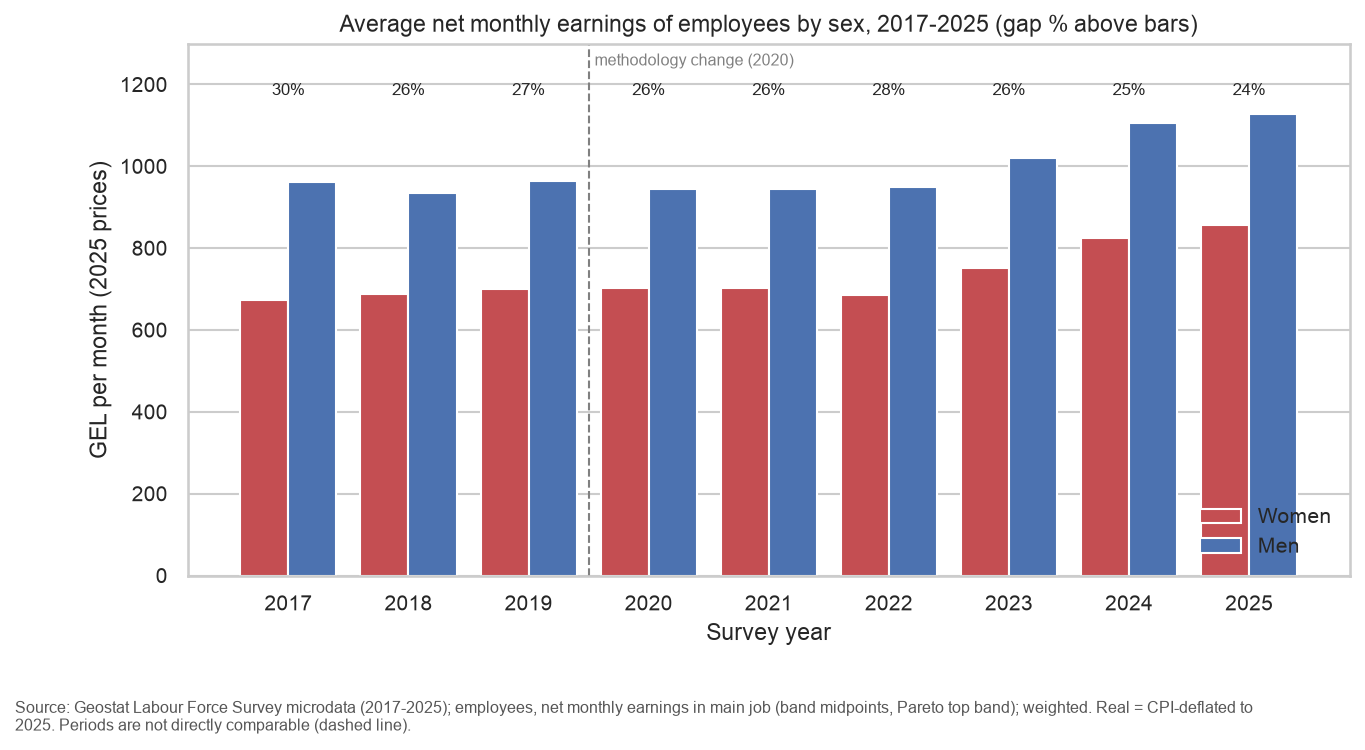

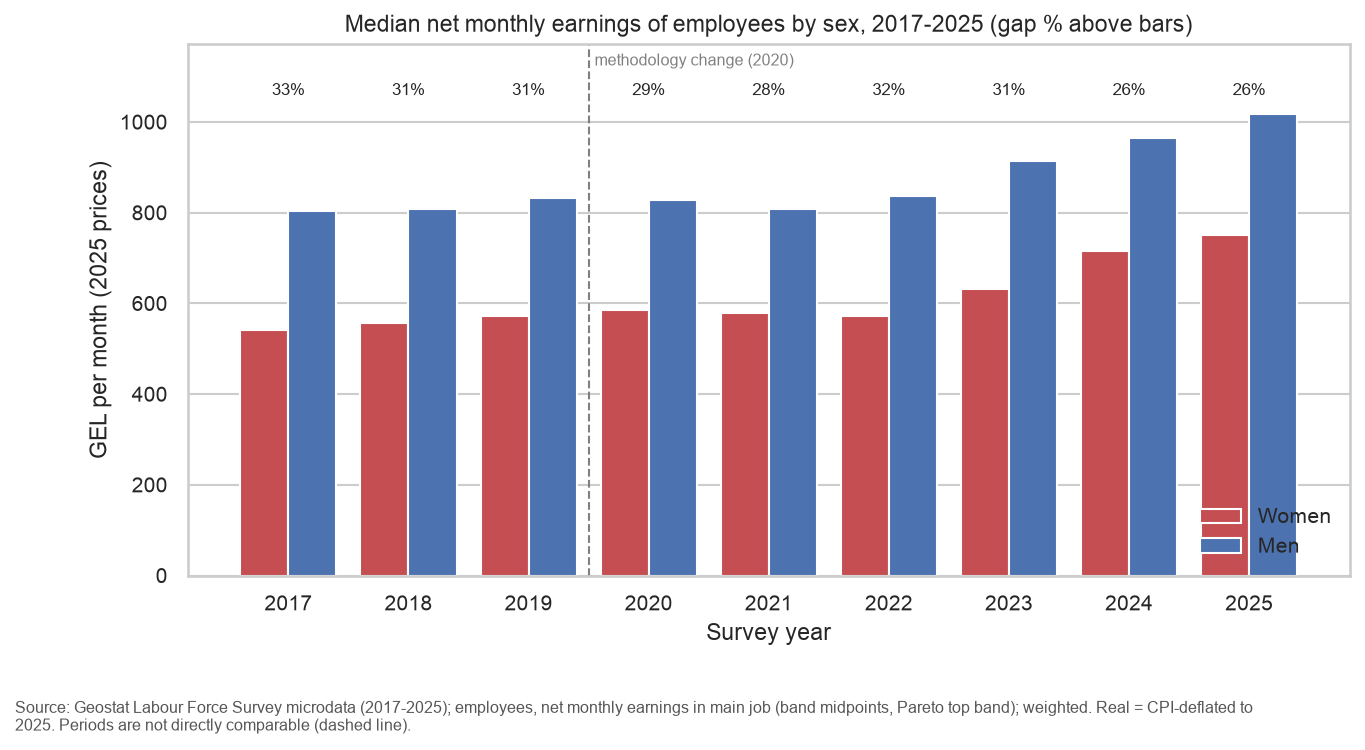

In [5]:
display(Image('../reports/figures/01_male_vs_female_mean_income.png'))
display(Image('../reports/figures/02_male_vs_female_median_income.png'))

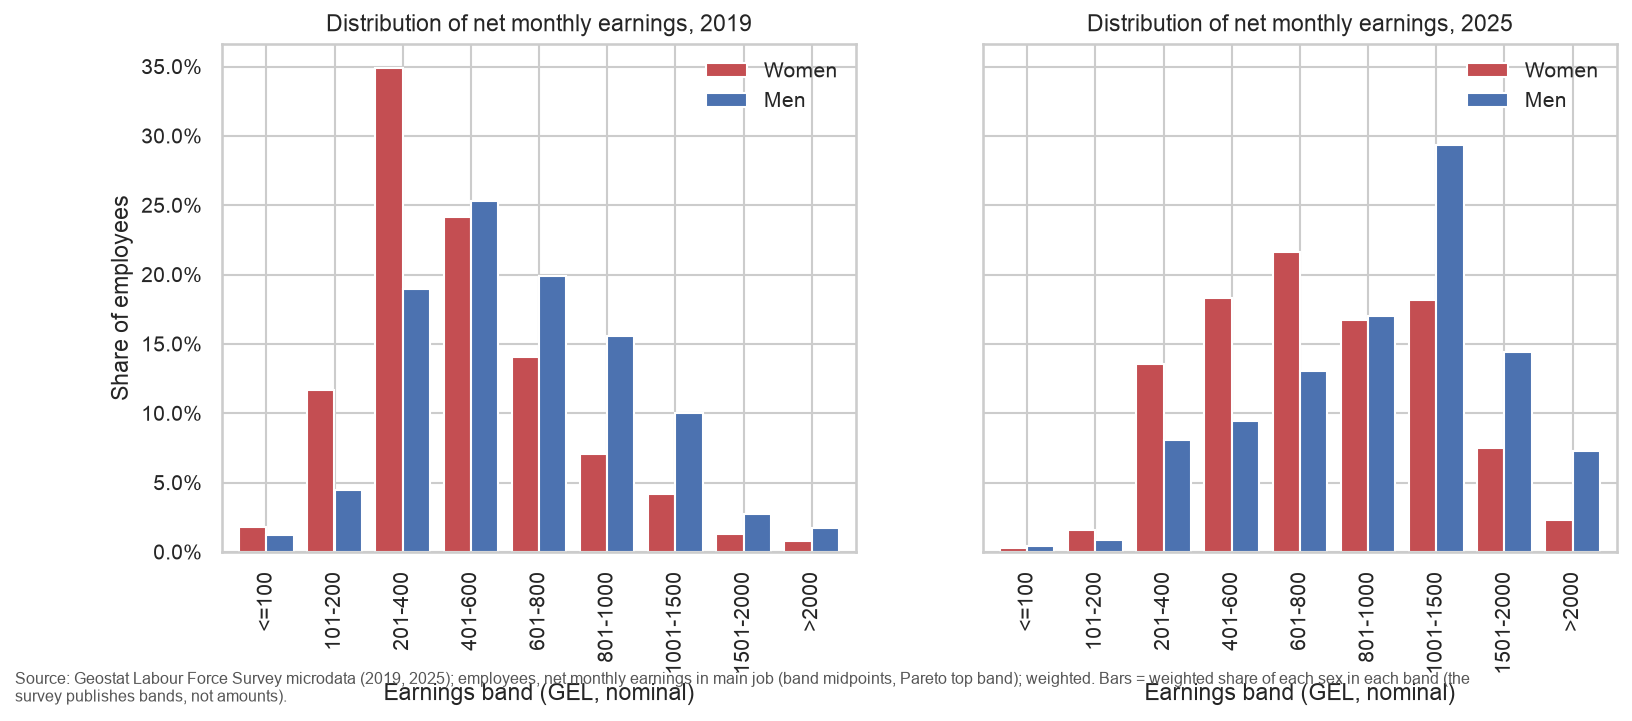

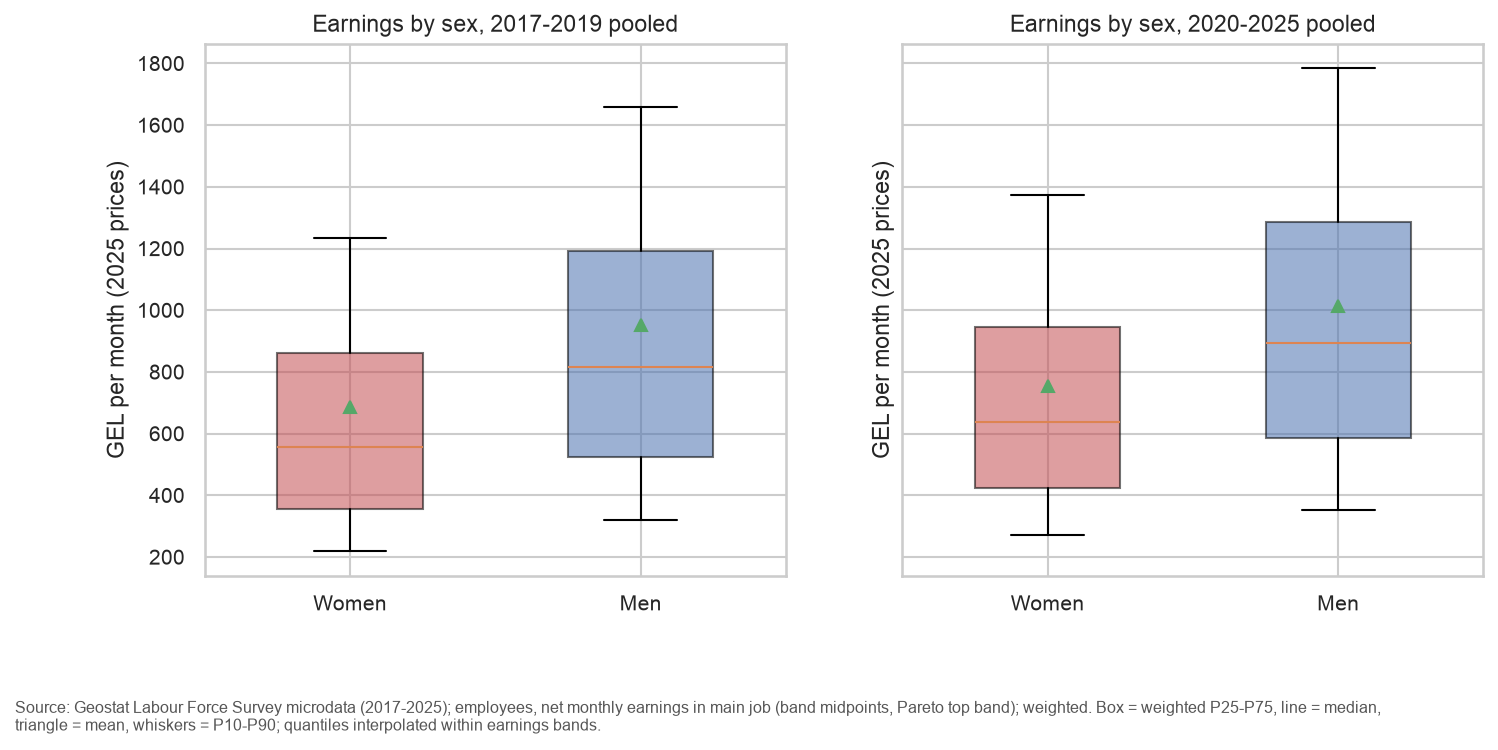

,period,quintile,real_upper_bound,population_share,female_share,n
0,2017_2019,1,366.7,0.123,0.690,5996
1,2017_2019,2,569.6,0.286,0.631,12242
2,2017_2019,3,804.2,0.243,0.476,9710
3,2017_2019,4,1144.3,0.154,0.407,5677
4,2017_2019,5,NaN,0.193,0.309,6516
5,2020_2025,1,430.2,0.195,0.663,19583
6,2020_2025,2,639.3,0.194,0.633,15835
7,2020_2025,3,878.9,0.185,0.540,14042
8,2020_2025,4,1238.4,0.181,0.426,13577
9,2020_2025,5,NaN,0.244,0.351,18129


In [6]:
display(Image('../reports/figures/03_income_distribution_histogram.png'))
display(Image('../reports/figures/04_gender_income_boxplot.png'))
r['groups']

## 4. Age

,period,group_variable,group,n_female,n_male,reliability,female_share,all_mean,all_median,all_p25,all_p75,female_mean,male_mean,female_median,male_median,female_sd,male_sd,female_mean_hours,male_mean_hours,gap_mean_pct,gap_median_pct,income_basis
0,2017_2019,age_group,15-17,30,48,low_n,0.42,765.84,464.22,284.14,706.72,1034.34,569.41,445.01,475.36,1564.14,511.91,42.57,50.28,-81.65,6.38,"real 2025 GEL, weighted (pooled period)"
1,2017_2019,age_group,18-24,1157,1869,ok,0.41,720.55,625.53,398.06,903.35,599.11,804.09,518.25,714.63,405.09,540.62,43.18,48.24,25.49,27.48,"real 2025 GEL, weighted (pooled period)"
2,2017_2019,age_group,25-34,4127,5284,ok,0.45,910.74,786.70,502.19,1158.13,767.48,1026.19,658.32,898.29,525.14,660.25,41.60,49.24,25.21,26.71,"real 2025 GEL, weighted (pooled period)"
3,2017_2019,age_group,35-44,4699,4290,ok,0.50,880.86,728.92,442.21,1122.48,702.78,1062.80,558.15,924.48,556.05,738.70,40.34,49.40,33.87,39.63,"real 2025 GEL, weighted (pooled period)"
4,2017_2019,age_group,45-54,4721,3992,ok,0.55,812.63,681.14,414.68,1028.03,707.51,940.37,568.53,803.83,577.78,675.27,40.25,47.31,24.76,29.27,"real 2025 GEL, weighted (pooled period)"
5,2017_2019,age_group,55-64,3847,3365,ok,0.55,742.37,593.17,362.67,926.10,647.17,857.95,513.91,712.73,530.67,674.65,37.91,45.16,24.57,27.90,"real 2025 GEL, weighted (pooled period)"
6,2017_2019,age_group,65+,1534,1178,ok,0.57,614.19,506.97,299.93,797.76,520.14,739.63,453.93,610.99,367.19,563.68,33.62,43.14,29.68,25.71,"real 2025 GEL, weighted (pooled period)"
7,2020_2025,age_group,15-17,51,61,low_n,0.45,532.28,488.97,321.60,724.17,536.44,528.81,458.30,520.97,234.78,358.58,32.18,35.68,-1.44,12.03,"real 2025 GEL, weighted (pooled period)"
8,2020_2025,age_group,18-24,1819,3139,ok,0.41,827.02,713.08,508.42,997.10,728.57,896.04,656.28,773.53,411.23,584.73,41.48,45.47,18.69,15.16,"real 2025 GEL, weighted (pooled period)"
9,2020_2025,age_group,25-34,6727,8797,ok,0.46,991.85,859.48,577.37,1231.97,826.90,1129.85,708.72,983.99,531.83,643.07,40.26,46.41,26.81,27.98,"real 2025 GEL, weighted (pooled period)"


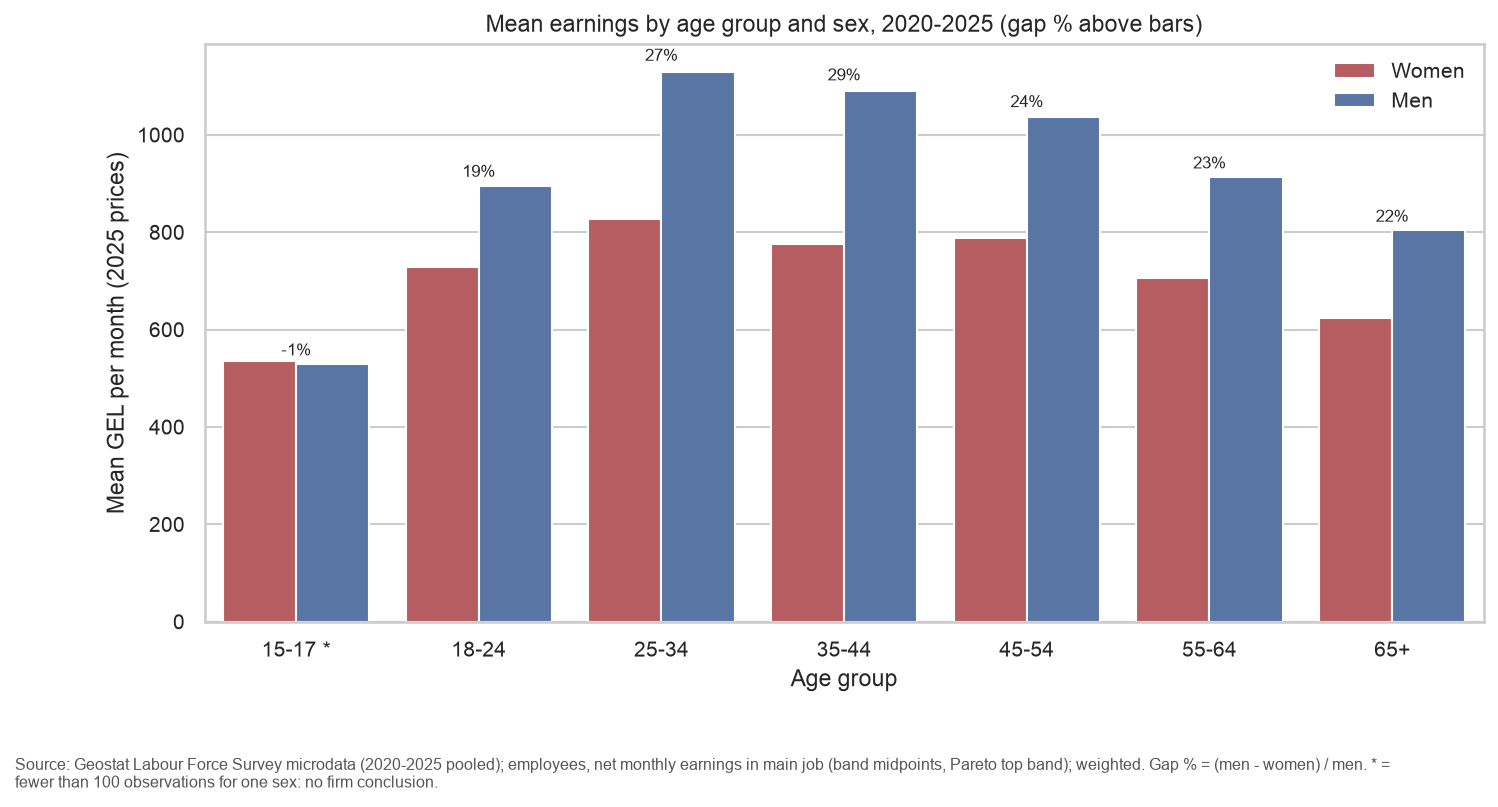

In [7]:
display(r['tables']['age'])
display(Image('../reports/figures/05_income_by_age_group.png'))

## 5. Education

,period,group_variable,group,n_female,n_male,reliability,female_share,all_mean,all_median,all_p25,all_p75,female_mean,male_mean,female_median,male_median,female_sd,male_sd,female_mean_hours,male_mean_hours,gap_mean_pct,gap_median_pct,mapping,income_basis
0,2017_2019,education_eda,Below secondary,445,851,ok,0.35,624.93,511.39,324.86,799.10,522.69,679.70,412.05,590.20,562.24,439.11,44.38,51.24,23.10,30.19,"source codes 1, 2, 3, 4, 5","real 2025 GEL, weighted (pooled period)"
1,2017_2019,education_eda,Secondary general,3659,7337,ok,0.34,707.86,614.18,380.69,924.35,527.10,799.92,449.16,727.93,362.32,485.07,46.05,49.97,34.11,38.30,source codes 6,"real 2025 GEL, weighted (pooled period)"
2,2017_2019,education_eda,Vocational,5131,4422,ok,0.53,646.93,527.00,329.40,818.85,505.37,806.46,428.43,709.09,390.23,583.88,42.69,48.54,37.34,39.58,"source codes 7, 8, 9","real 2025 GEL, weighted (pooled period)"
3,2017_2019,education_eda,Higher professional,23,16,suppressed,0.56,840.21,847.71,509.73,1170.16,NaN,NaN,NaN,NaN,278.68,404.84,42.29,52.95,NaN,NaN,source codes 10,"real 2025 GEL, weighted (pooled period)"
4,2017_2019,education_eda,Bachelor,2702,2263,ok,0.52,947.91,816.56,529.62,1174.60,765.54,1147.80,673.13,1022.68,548.43,693.37,40.01,48.02,33.30,34.18,source codes 11,"real 2025 GEL, weighted (pooled period)"
5,2017_2019,education_eda,Master,8016,5059,ok,0.61,951.97,795.07,498.51,1177.49,815.87,1161.29,697.78,987.58,600.02,824.79,35.93,44.90,29.74,29.35,source codes 12,"real 2025 GEL, weighted (pooled period)"
6,2017_2019,education_eda,Doctor,139,78,low_n,0.63,1274.70,1049.65,686.20,1607.07,1007.69,1732.18,844.44,1530.69,626.38,995.54,34.37,29.08,41.83,44.83,source codes 13,"real 2025 GEL, weighted (pooled period)"
7,2020_2025,education_eda,Below secondary,987,1629,ok,0.38,632.50,538.73,300.11,821.61,502.26,713.68,444.85,614.20,325.92,490.30,39.85,45.73,29.62,27.57,"source codes 1, 2, 3, 4, 5","real 2025 GEL, weighted (pooled period)"
8,2020_2025,education_eda,Secondary general,9807,17648,ok,0.38,778.31,673.10,435.68,975.29,593.55,890.83,527.43,798.49,378.63,533.96,42.23,46.67,33.37,33.95,source codes 6,"real 2025 GEL, weighted (pooled period)"
9,2020_2025,education_eda,Vocational,10462,7291,ok,0.60,703.48,579.59,384.62,864.61,567.21,905.43,501.82,783.91,352.87,599.50,41.63,46.36,37.35,35.98,"source codes 7, 8, 9","real 2025 GEL, weighted (pooled period)"


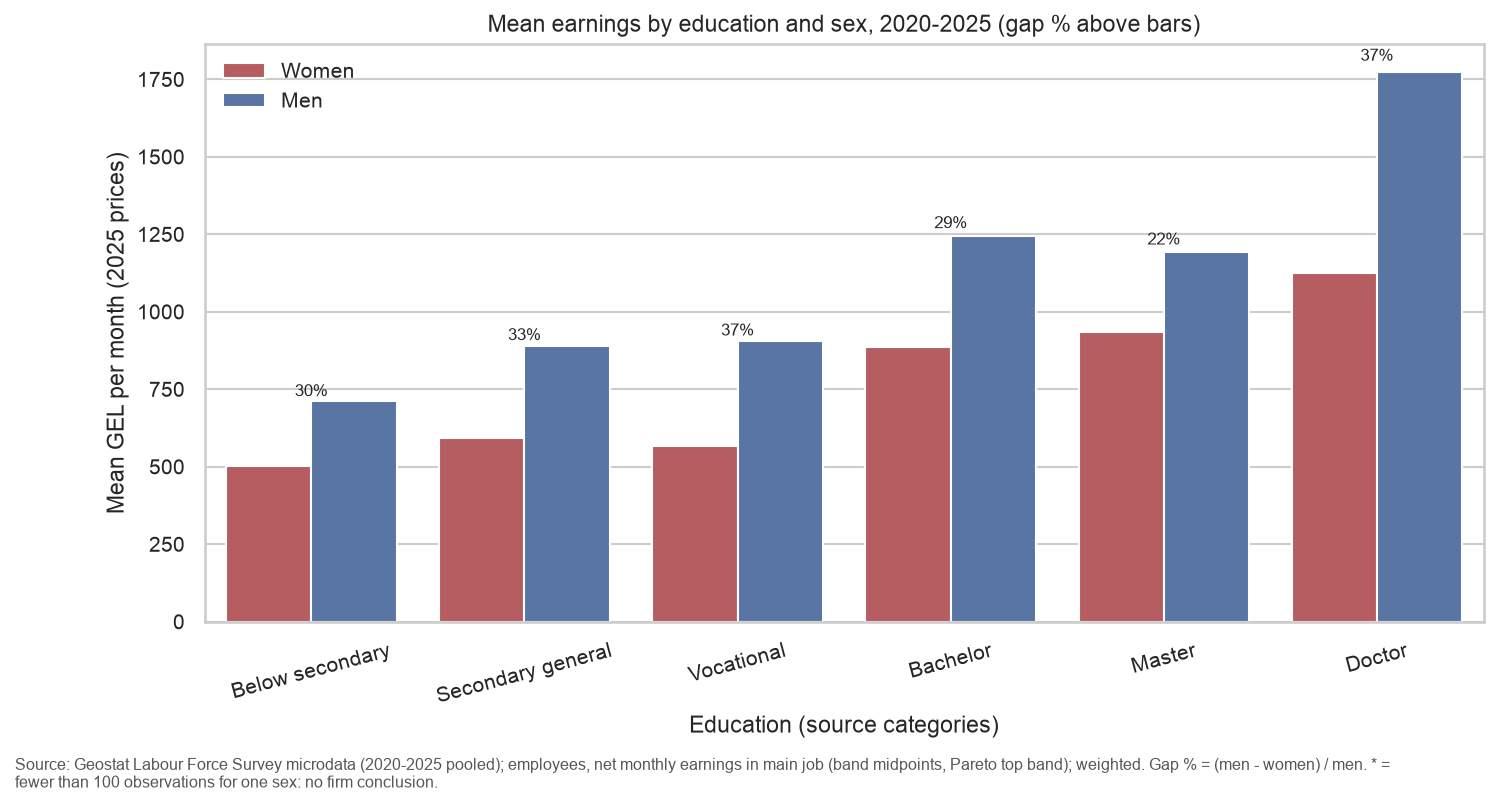

In [8]:
display(r['tables']['education'])
display(Image('../reports/figures/06_income_by_education.png'))

## 6. Regions

,period,group_variable,group,n_female,n_male,reliability,female_share,all_mean,all_median,all_p25,all_p75,female_mean,male_mean,female_median,male_median,female_sd,male_sd,female_mean_hours,male_mean_hours,gap_mean_pct,gap_median_pct,income_basis
9,2017_2019,region_eda,Tbilisi,3537,2876,ok,0.54,977.91,820.11,531.65,1202.12,837.36,1141.69,697.79,990.77,641.91,762.43,40.19,46.94,26.66,29.57,"real 2025 GEL, weighted (pooled period)"
0,2017_2019,region_eda,Adjara A/R,2744,2660,ok,0.51,861.16,679.44,425.37,1045.58,687.63,1038.71,546.91,809.62,502.33,871.38,40.08,46.61,33.80,32.45,"real 2025 GEL, weighted (pooled period)"
4,2017_2019,region_eda,Kvemo Kartli,1807,2057,ok,0.45,783.69,678.27,425.56,1002.61,630.51,909.12,526.63,805.39,449.58,552.81,40.54,48.44,30.65,34.61,"real 2025 GEL, weighted (pooled period)"
6,2017_2019,region_eda,Samegrelo-Zemo Svaneti,1792,1845,ok,0.49,736.86,620.58,390.90,954.82,611.58,857.93,517.49,751.61,416.42,543.76,40.43,49.95,28.71,31.15,"real 2025 GEL, weighted (pooled period)"
5,2017_2019,region_eda,Mtskheta-Mtianeti,1421,1493,ok,0.48,710.13,635.63,403.38,878.55,583.61,826.54,533.89,735.19,326.12,527.84,41.25,48.98,29.39,27.38,"real 2025 GEL, weighted (pooled period)"
7,2017_2019,region_eda,Samtskhe-Javakheti,1152,1344,ok,0.48,706.06,611.40,358.25,936.60,539.38,857.56,464.32,788.19,358.94,481.93,35.77,49.89,37.10,41.09,"real 2025 GEL, weighted (pooled period)"
8,2017_2019,region_eda,Shida Kartli,1817,2146,ok,0.46,697.57,595.76,336.29,921.85,545.64,828.82,450.66,741.55,407.27,526.42,40.68,51.46,34.17,39.23,"real 2025 GEL, weighted (pooled period)"
1,2017_2019,region_eda,Guria,1239,1241,ok,0.50,696.80,559.03,334.28,912.80,569.19,822.96,454.60,712.02,435.20,591.03,37.40,46.60,30.84,36.15,"real 2025 GEL, weighted (pooled period)"
2,2017_2019,region_eda,Imereti + Racha-Lechkhumi & Kvemo Svaneti,2709,2772,ok,0.48,660.50,549.77,334.31,867.61,540.21,769.19,451.48,681.21,375.66,506.36,38.62,45.98,29.77,33.72,"real 2025 GEL, weighted (pooled period)"
3,2017_2019,region_eda,Kakheti,1897,1592,ok,0.53,587.35,483.60,288.30,766.63,510.04,674.95,429.58,555.78,390.34,494.93,39.37,50.39,24.43,22.71,"real 2025 GEL, weighted (pooled period)"


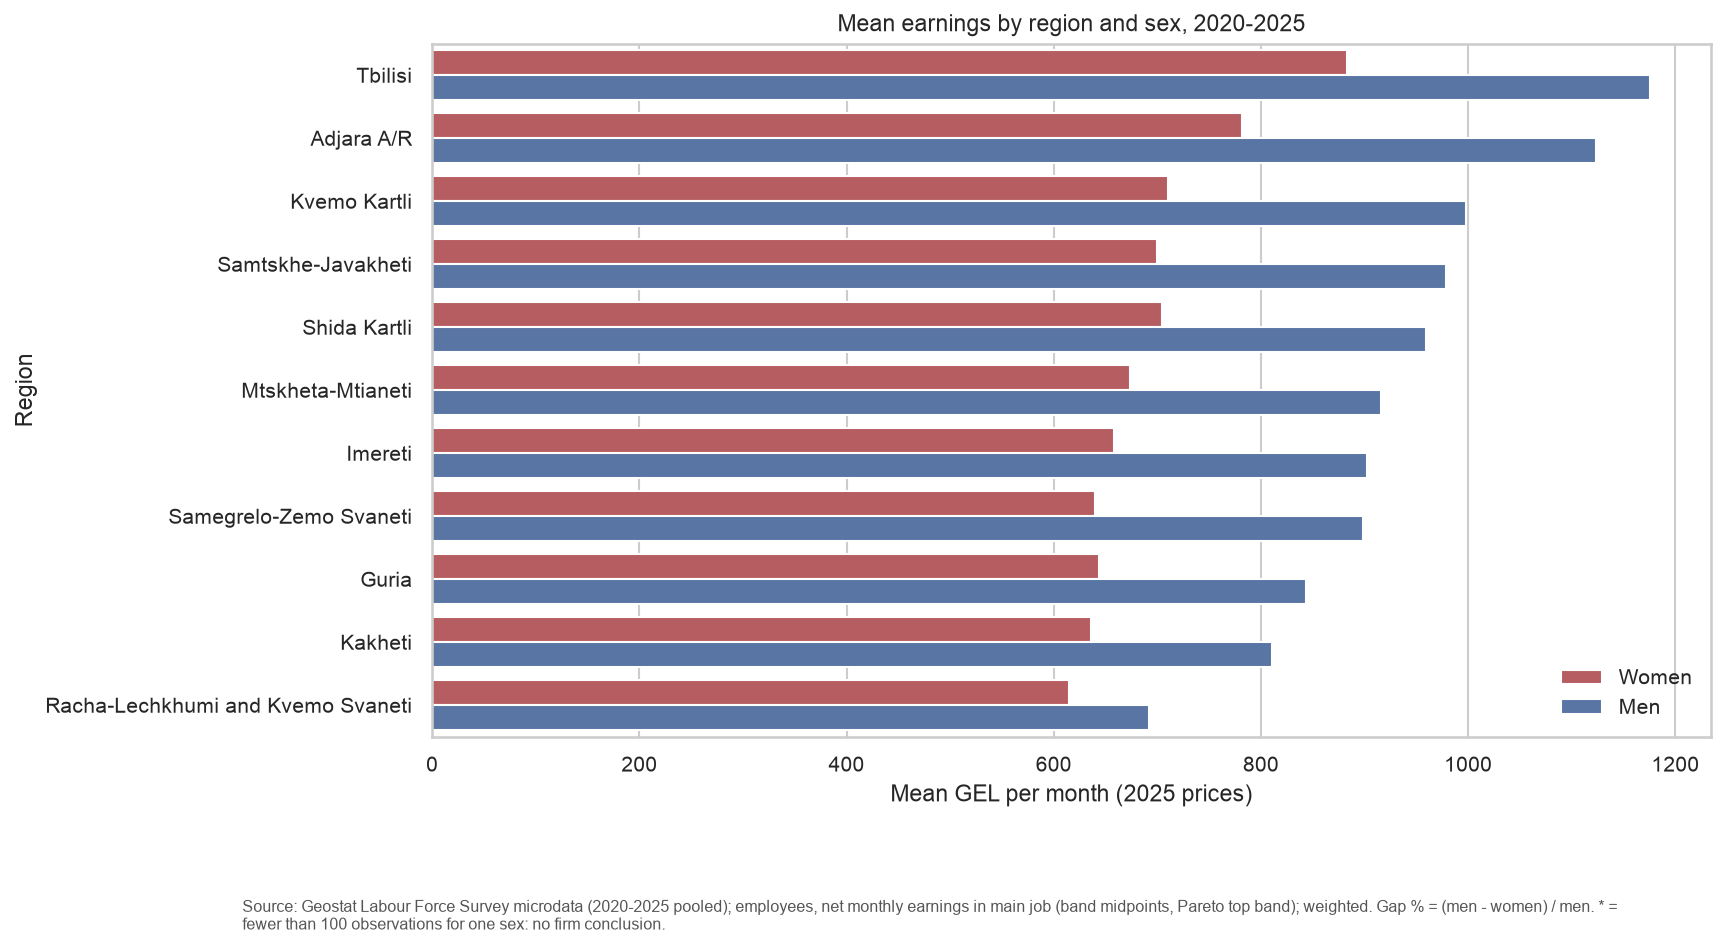

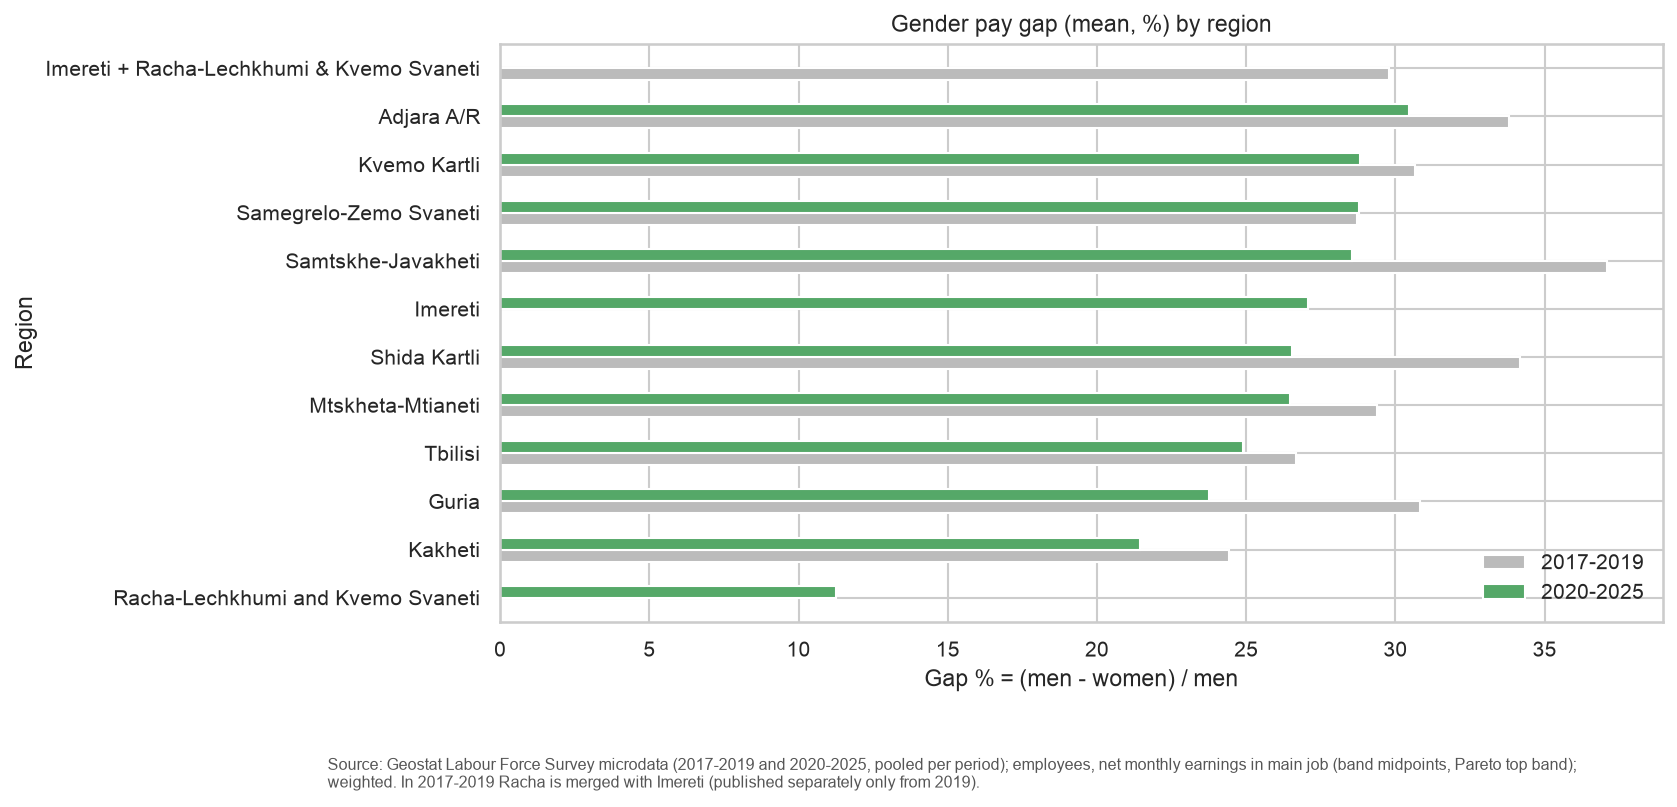

In [9]:
display(r['tables']['region'])
display(Image('../reports/figures/07_regional_income_comparison.png'))
display(Image('../reports/figures/09_gender_pay_gap_by_region.png'))

## 7. Occupation and industry

,period,group_variable,group,n_female,n_male,reliability,female_share,all_mean,all_median,all_p25,all_p75,female_mean,male_mean,female_median,male_median,female_sd,male_sd,female_mean_hours,male_mean_hours,gap_mean_pct,gap_median_pct,income_basis
1,2017_2019,occupation_label,Managers,1001,1574,ok,0.39,1380.11,1142.68,784.22,1605.47,1169.57,1516.81,989.14,1245.99,815.32,1034.26,43.42,46.24,22.89,20.61,"real 2025 GEL, weighted (pooled period)"
0,2017_2019,occupation_label,Armed forces / other,6,481,suppressed,0.02,1358.95,1315.81,1177.44,1481.75,NaN,NaN,NaN,NaN,437.63,410.01,44.83,51.61,NaN,NaN,"real 2025 GEL, weighted (pooled period)"
2,2017_2019,occupation_label,Professionals,6602,2151,ok,0.73,919.34,769.87,484.46,1133.53,808.77,1214.09,702.44,1039.70,582.47,830.15,31.80,38.82,33.38,32.44,"real 2025 GEL, weighted (pooled period)"
8,2017_2019,occupation_label,Plant & machine operators,191,3084,ok,0.06,880.32,792.38,559.12,1080.14,553.62,901.21,521.99,811.25,267.67,540.83,46.75,48.51,38.57,35.66,"real 2025 GEL, weighted (pooled period)"
7,2017_2019,occupation_label,Craft & trades,757,3198,ok,0.18,792.67,722.36,471.36,1021.90,528.00,850.83,481.28,780.38,307.00,470.47,47.63,49.36,37.94,38.33,"real 2025 GEL, weighted (pooled period)"
3,2017_2019,occupation_label,Technicians & assoc. prof.,3380,2243,ok,0.59,775.85,625.84,384.51,999.48,611.02,1011.66,497.03,879.00,491.65,695.74,39.57,45.32,39.60,43.46,"real 2025 GEL, weighted (pooled period)"
4,2017_2019,occupation_label,Clerical support,2149,1060,ok,0.65,728.46,674.01,426.35,936.07,648.16,877.33,592.13,798.11,355.28,464.22,42.63,46.04,26.12,25.81,"real 2025 GEL, weighted (pooled period)"
5,2017_2019,occupation_label,Service & sales,3541,2776,ok,0.56,665.37,541.01,348.25,826.11,580.05,776.32,471.38,675.52,463.34,513.16,50.12,54.25,25.28,30.22,"real 2025 GEL, weighted (pooled period)"
6,2017_2019,occupation_label,Skilled agricultural,89,251,low_n,0.26,595.68,522.88,321.84,759.27,448.38,647.81,393.96,569.37,273.94,434.39,48.42,48.23,30.79,30.81,"real 2025 GEL, weighted (pooled period)"
9,2017_2019,occupation_label,Elementary occupations,2399,3207,ok,0.46,552.85,461.82,277.75,723.41,463.73,627.15,395.33,547.63,345.12,416.43,41.34,51.25,26.06,27.81,"real 2025 GEL, weighted (pooled period)"


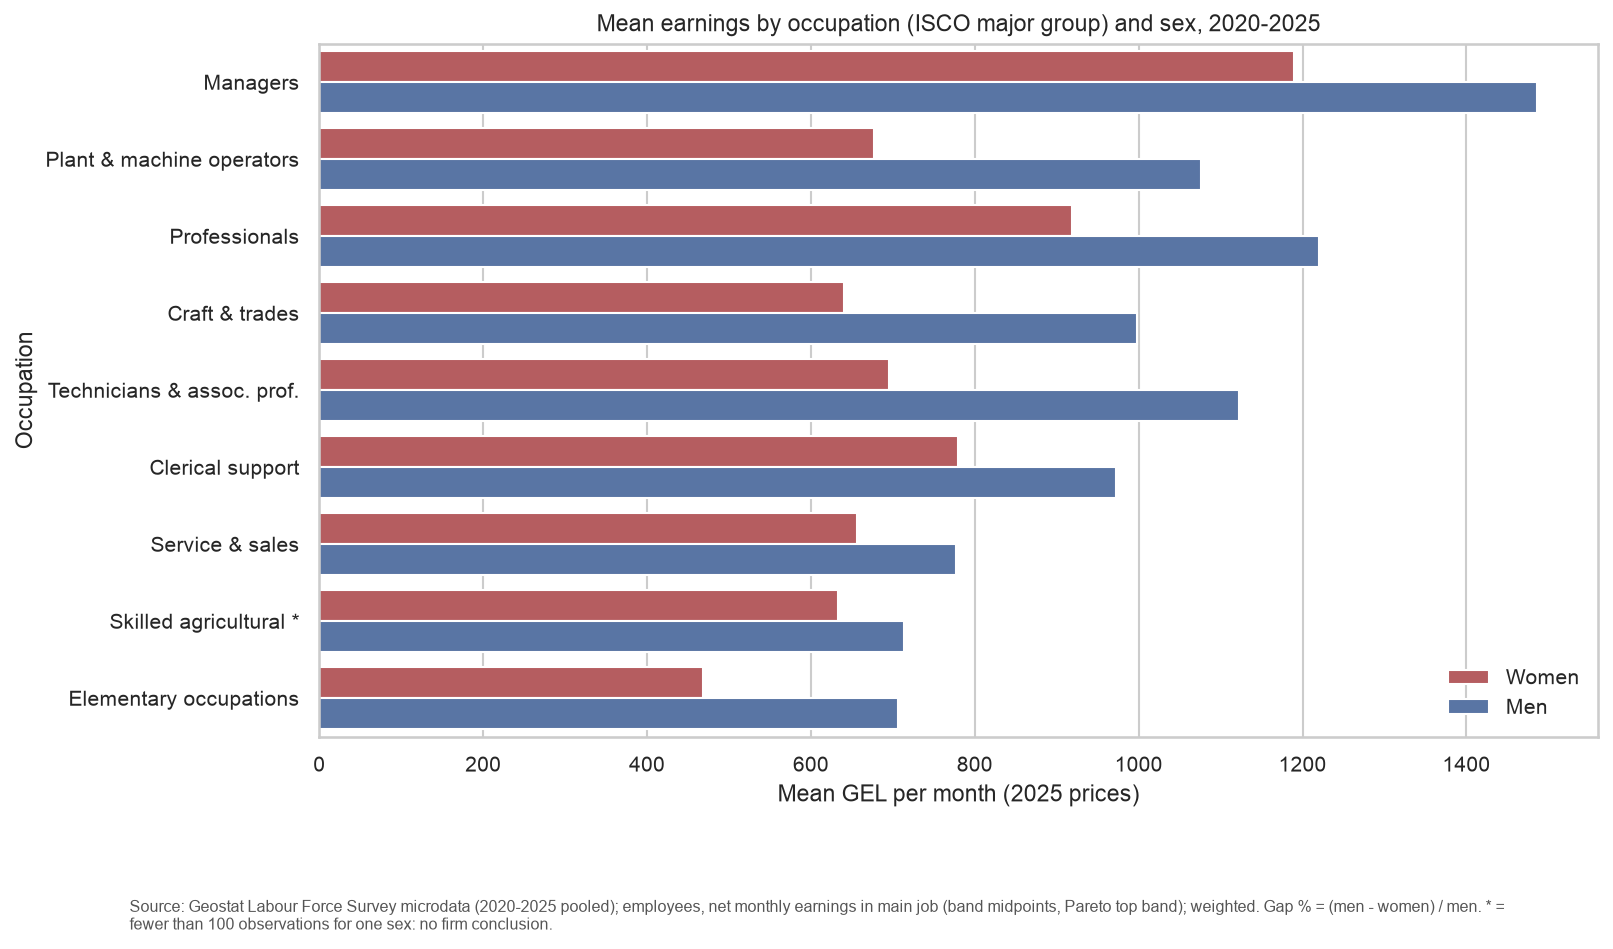

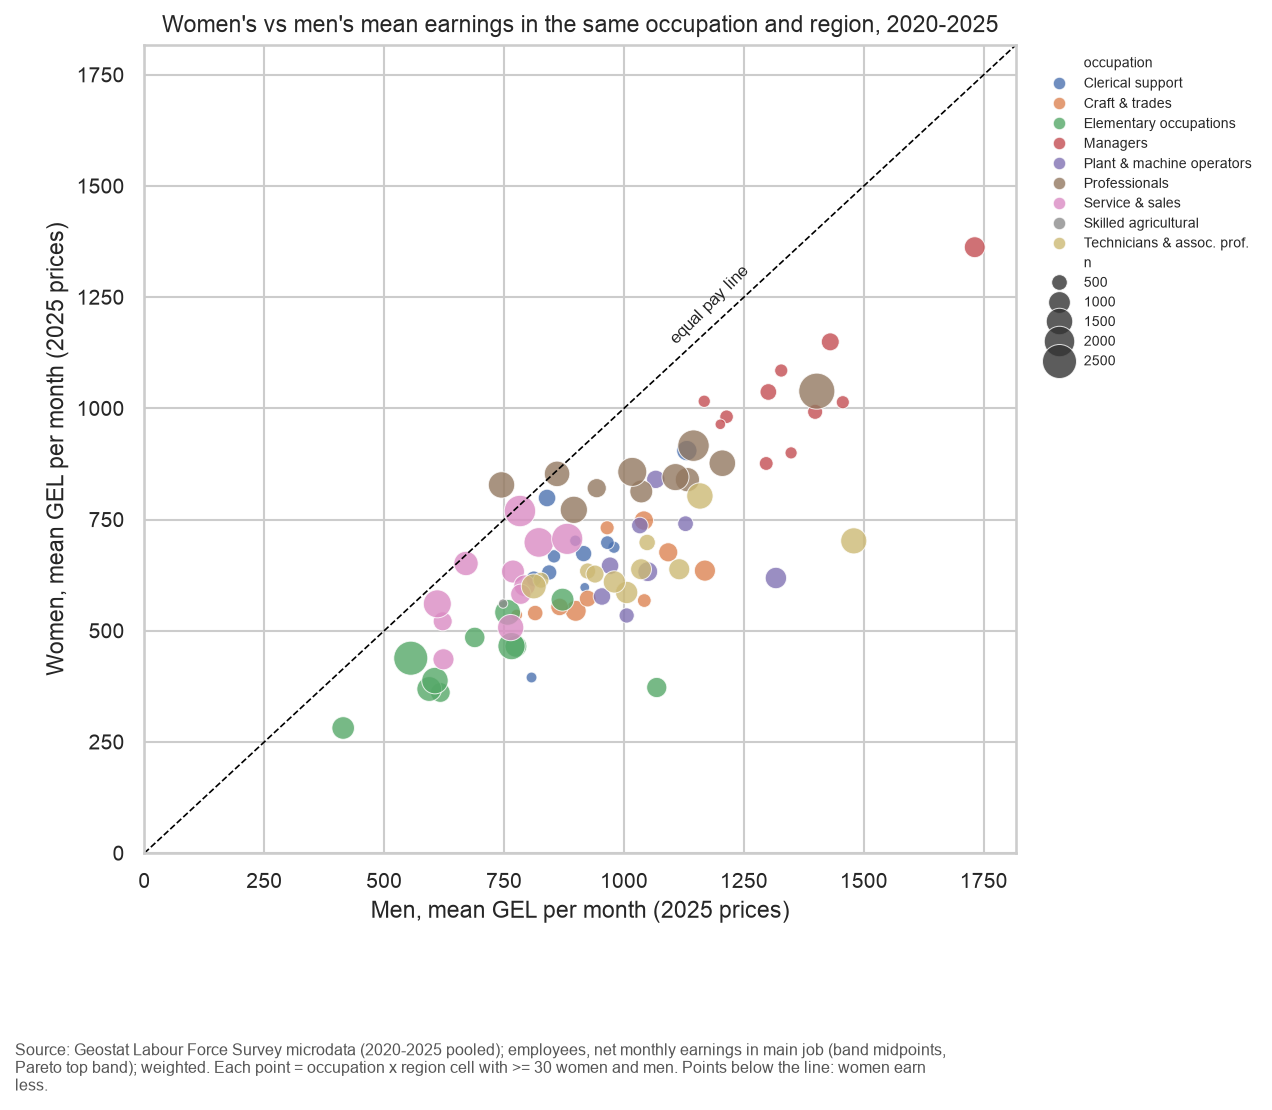

In [10]:
display(r['tables']['occupation'])
display(Image('../reports/figures/08_occupation_income_comparison.png'))
display(Image('../reports/figures/11_gender_income_scatter.png'))

## 8. Working hours: monthly vs hourly gap

,period,group_variable,group,n_female,n_male,reliability,female_share,all_mean,all_median,all_p25,all_p75,female_mean,male_mean,female_median,male_median,female_sd,male_sd,female_mean_hours,male_mean_hours,gap_mean_pct,gap_median_pct,income_basis
0,2017_2019,hours_band,1-19,2165,608,ok,0.78,529.44,469.71,261.96,725.50,521.19,557.89,479.09,438.30,327.21,489.83,13.78,12.05,6.58,-9.31,"real 2025 GEL, weighted (pooled period)"
1,2017_2019,hours_band,20-34,3056,1114,ok,0.74,592.58,500.27,294.41,784.41,567.68,664.45,481.01,556.71,414.23,487.11,26.40,27.14,14.56,13.60,"real 2025 GEL, weighted (pooled period)"
2,2017_2019,hours_band,35-40,7021,5232,ok,0.58,873.89,732.67,452.35,1086.45,768.15,1017.38,621.56,875.55,614.70,700.38,39.19,39.38,24.50,29.01,"real 2025 GEL, weighted (pooled period)"
3,2017_2019,hours_band,41-48,4014,4982,ok,0.45,851.86,732.81,469.41,1079.20,710.53,968.56,585.59,839.26,481.34,655.05,46.33,46.63,26.64,30.23,"real 2025 GEL, weighted (pooled period)"
4,2017_2019,hours_band,49-60,1916,3473,ok,0.36,878.37,734.74,457.31,1118.83,688.12,986.45,547.83,852.33,529.80,666.28,55.06,55.81,30.24,35.73,"real 2025 GEL, weighted (pooled period)"
5,2017_2019,hours_band,61+,1194,2707,ok,0.30,901.18,730.77,444.65,1174.82,735.06,971.59,538.49,812.95,634.59,710.80,73.90,73.88,24.34,33.76,"real 2025 GEL, weighted (pooled period)"
6,2020_2025,hours_band,1-19,4315,1442,ok,0.76,661.55,566.44,282.31,966.60,686.02,582.82,614.44,455.56,438.93,479.28,14.09,13.15,-17.71,-34.87,"real 2025 GEL, weighted (pooled period)"
7,2020_2025,hours_band,20-34,7102,3412,ok,0.69,678.03,545.89,323.10,924.24,678.65,676.64,538.46,562.39,456.72,462.97,25.81,26.48,-0.30,4.25,"real 2025 GEL, weighted (pooled period)"
8,2020_2025,hours_band,35-40,16671,13883,ok,0.56,939.19,794.10,511.52,1183.55,816.23,1095.30,674.43,947.10,558.89,657.03,39.36,39.53,25.48,28.79,"real 2025 GEL, weighted (pooled period)"
9,2020_2025,hours_band,41-48,8171,11269,ok,0.44,911.67,795.96,551.67,1112.46,737.88,1048.06,651.65,937.18,420.41,577.05,46.38,46.86,29.60,30.47,"real 2025 GEL, weighted (pooled period)"


,period,group_variable,group,n_female,n_male,reliability,female_share,all_mean,all_median,all_p25,all_p75,female_mean,male_mean,female_median,male_median,female_sd,male_sd,female_mean_hours,male_mean_hours,gap_mean_pct,gap_median_pct,income_basis
0,2017_2019,part_time,full-time,18682,19168,ok,0.50,840.31,706.65,436.99,1065.74,708.77,970.32,575.84,830.05,540.80,677.99,41.03,48.51,26.95,30.63,"real 2025 GEL, weighted (pooled period)"
1,2017_2019,part_time,part-time,1432,855,ok,0.63,437.76,332.54,194.48,550.85,380.91,533.46,289.85,415.30,343.27,467.36,20.95,27.26,28.60,30.21,"real 2025 GEL, weighted (pooled period)"
2,2020_2025,part_time,full-time,38653,38731,ok,0.51,901.54,774.04,505.72,1133.37,775.20,1032.69,654.90,910.03,502.63,620.38,39.97,46.12,24.93,28.04,"real 2025 GEL, weighted (pooled period)"
3,2020_2025,part_time,part-time,2239,1543,ok,0.64,440.41,356.64,232.77,561.88,425.96,466.51,349.53,371.91,289.57,354.25,20.33,26.84,8.69,6.02,"real 2025 GEL, weighted (pooled period)"


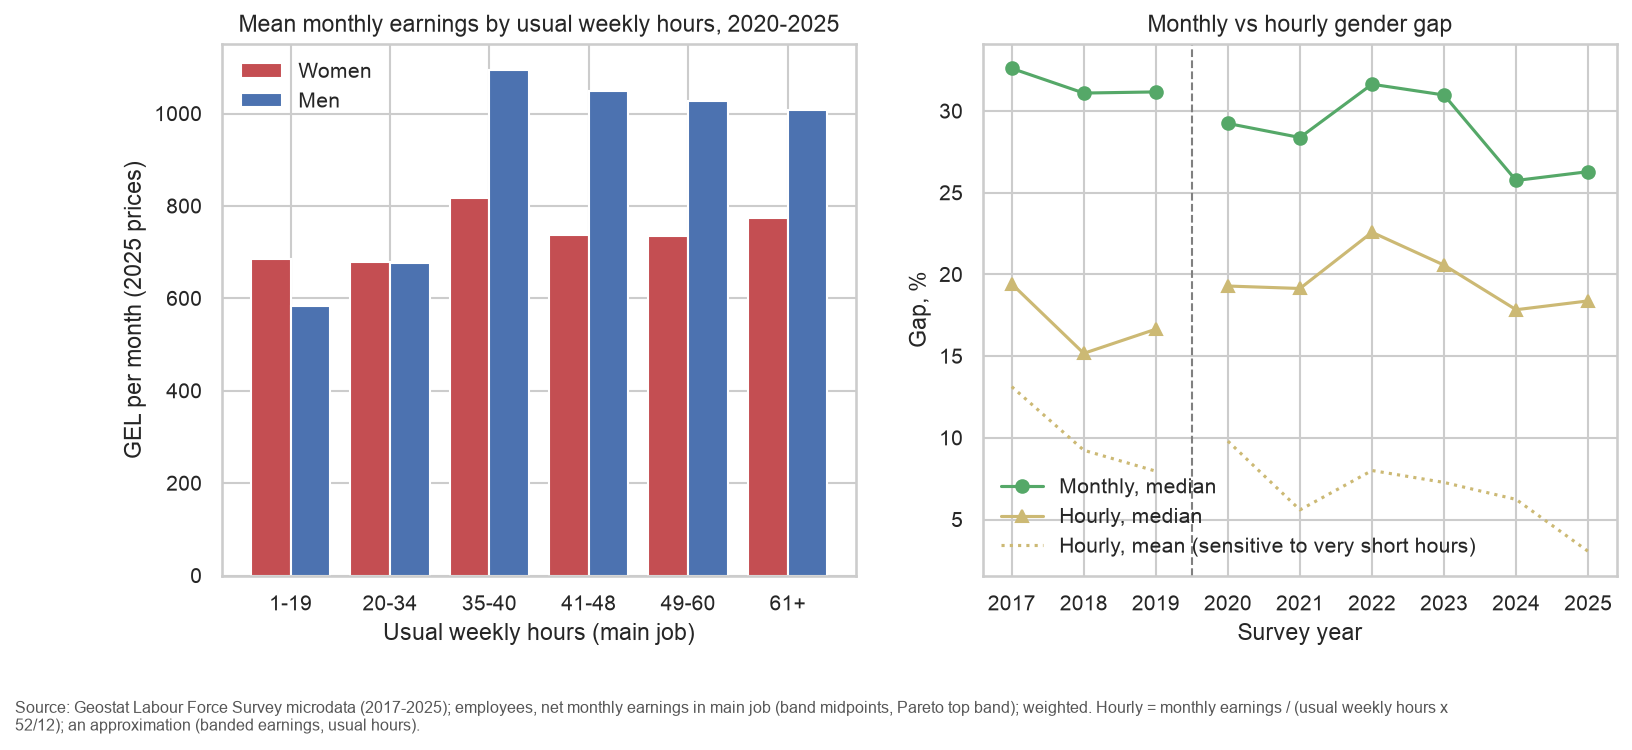

In [11]:
display(r['tables']['hours'])
display(r['tables']['part_time'])
display(Image('../reports/figures/13_working_hours_and_hourly_gap.png'))

## 9. Time series

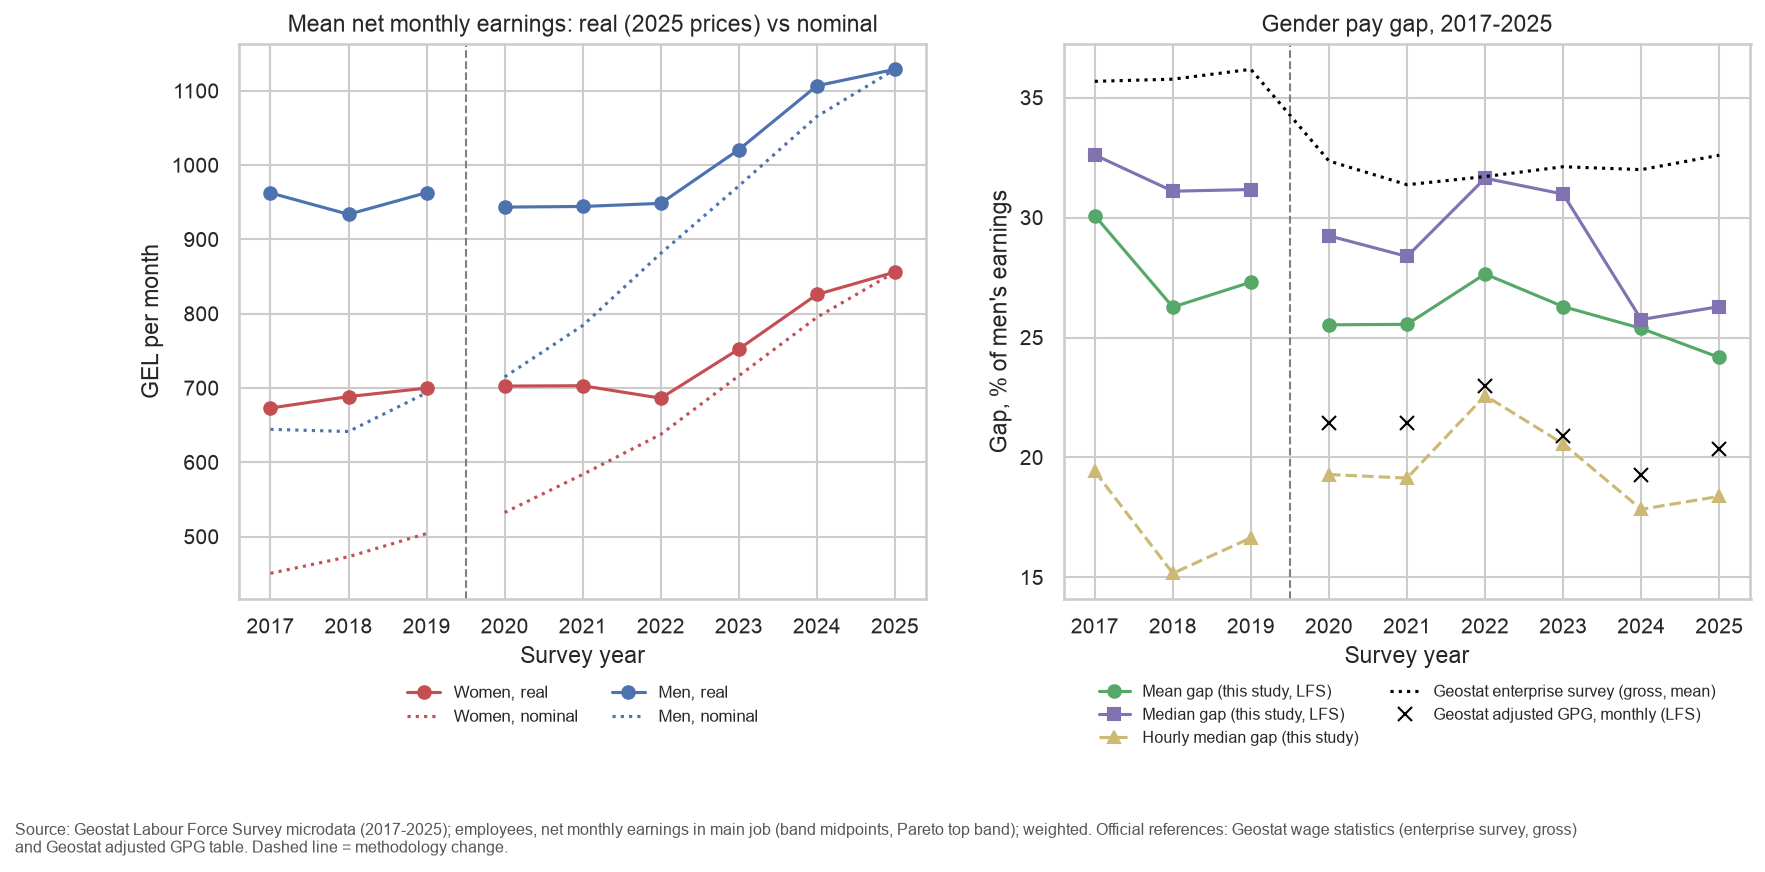

In [12]:
display(Image('../reports/figures/10_income_trends_by_year.png'))

## 10. Correlations (Spearman, not causal)

,log_real_income
log_real_income,1.000
female,-0.239
age,-0.139
years_schooling,0.239
potential_experience,-0.189
weekly_hours,0.168
part_time,-0.211
informal,-0.142
written_contract,0.135
public_sector,-0.069


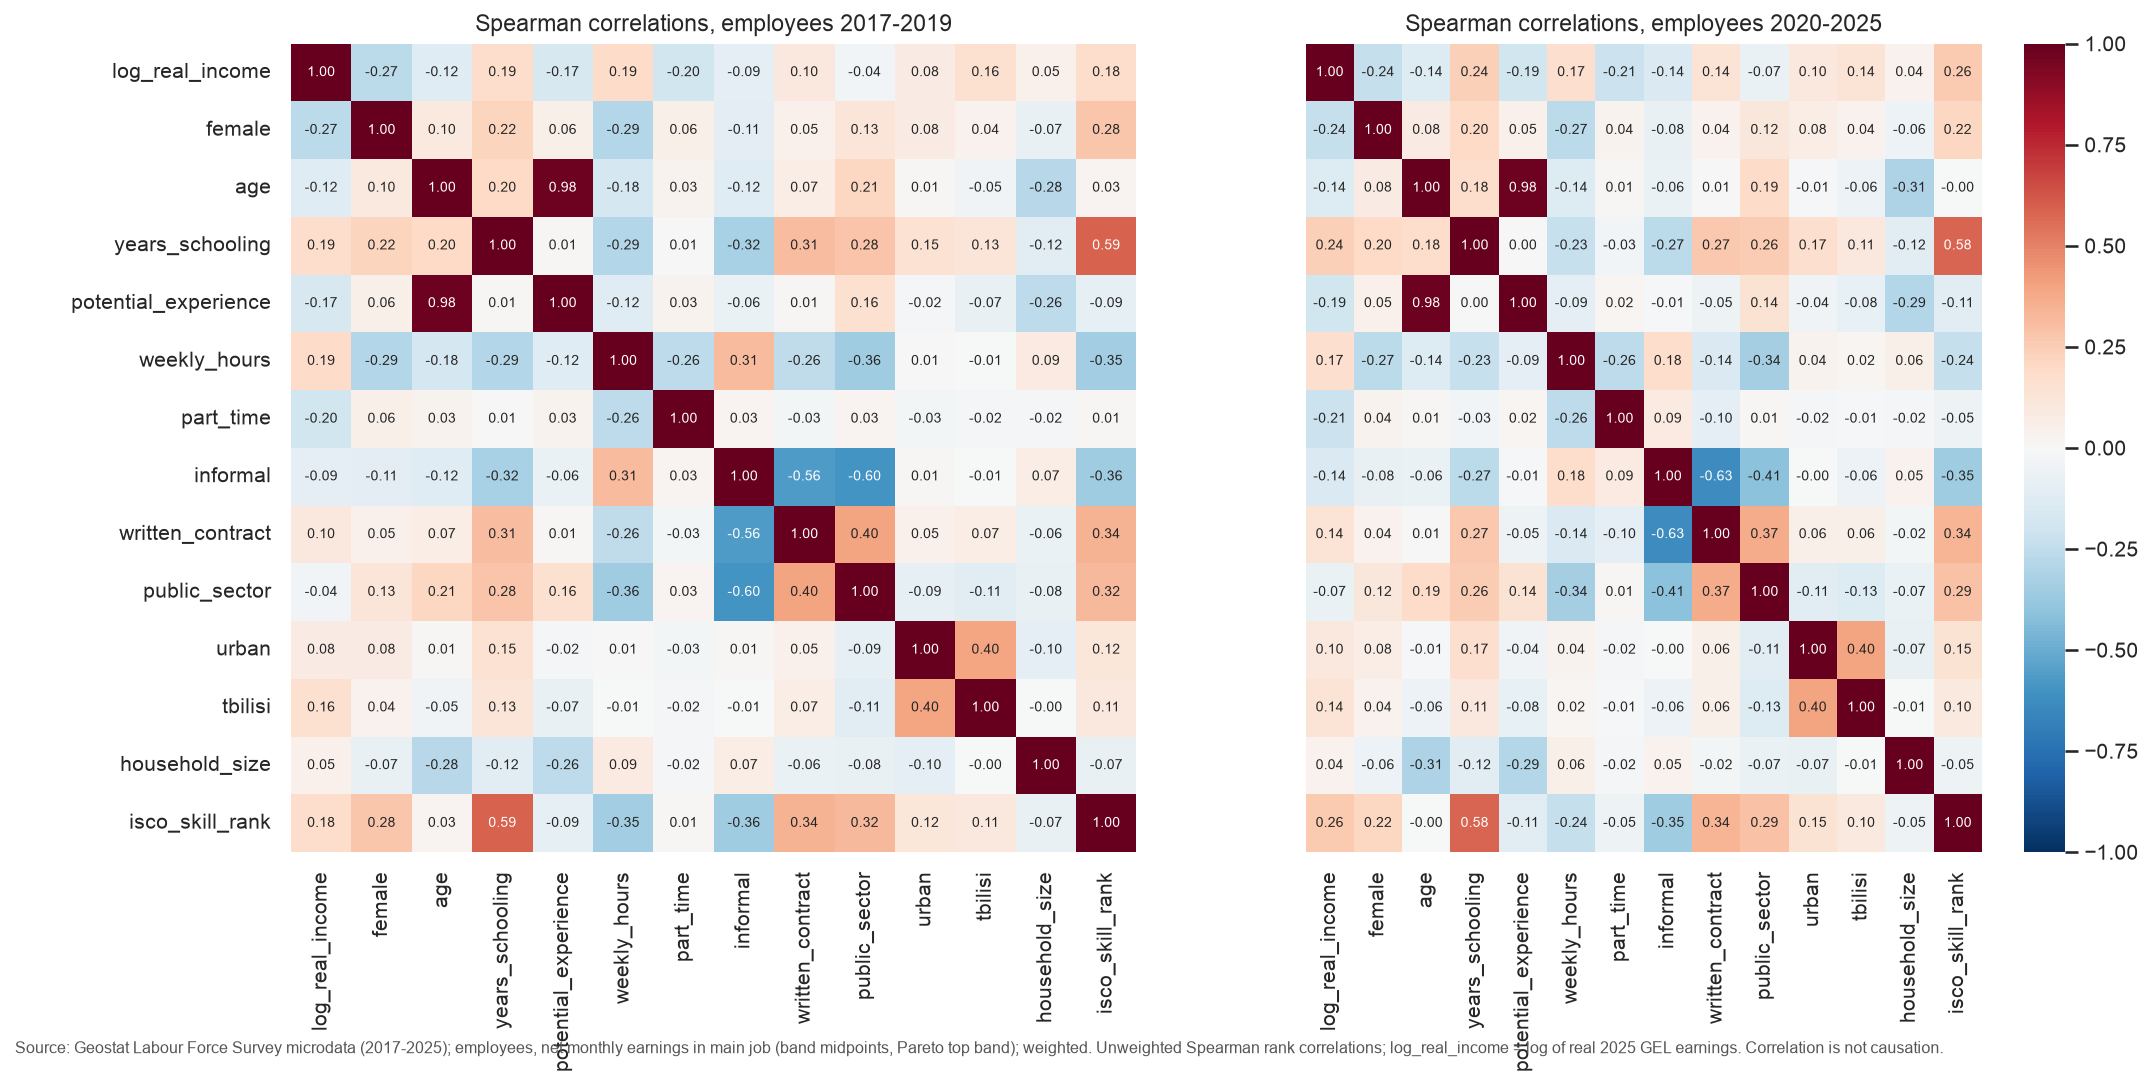

In [13]:
display(r['corr']['2020_2025'].loc[['log_real_income']].T)
display(Image('../reports/figures/12_correlation_heatmap.png'))

## 11. Household income (HIES) — separate, household-level

,year,head_sex,n_households,mean_per_capita_real,median_per_capita_real,mean_household_size,income_unit,currency,gap_mean_pct_per_capita
0,2017,female,3838,479.12,358.50,2.88,household (per capita),GEL (2025 prices),-6.22
1,2017,male,7718,451.08,345.18,3.84,household (per capita),GEL (2025 prices),-6.22
2,2018,female,3640,460.39,363.92,2.99,household (per capita),GEL (2025 prices),2.37
3,2018,male,7268,471.55,357.99,3.83,household (per capita),GEL (2025 prices),2.37
4,2019,female,4576,477.18,370.21,2.97,household (per capita),GEL (2025 prices),0.62
5,2019,male,9165,480.17,370.21,3.79,household (per capita),GEL (2025 prices),0.62
6,2020,female,4383,460.08,371.26,2.88,household (per capita),GEL (2025 prices),-2.25
7,2020,male,8757,449.94,361.74,3.74,household (per capita),GEL (2025 prices),-2.25
8,2021,female,4621,466.44,390.43,2.79,household (per capita),GEL (2025 prices),-0.65
9,2021,male,8809,463.42,372.52,3.68,household (per capita),GEL (2025 prices),-0.65


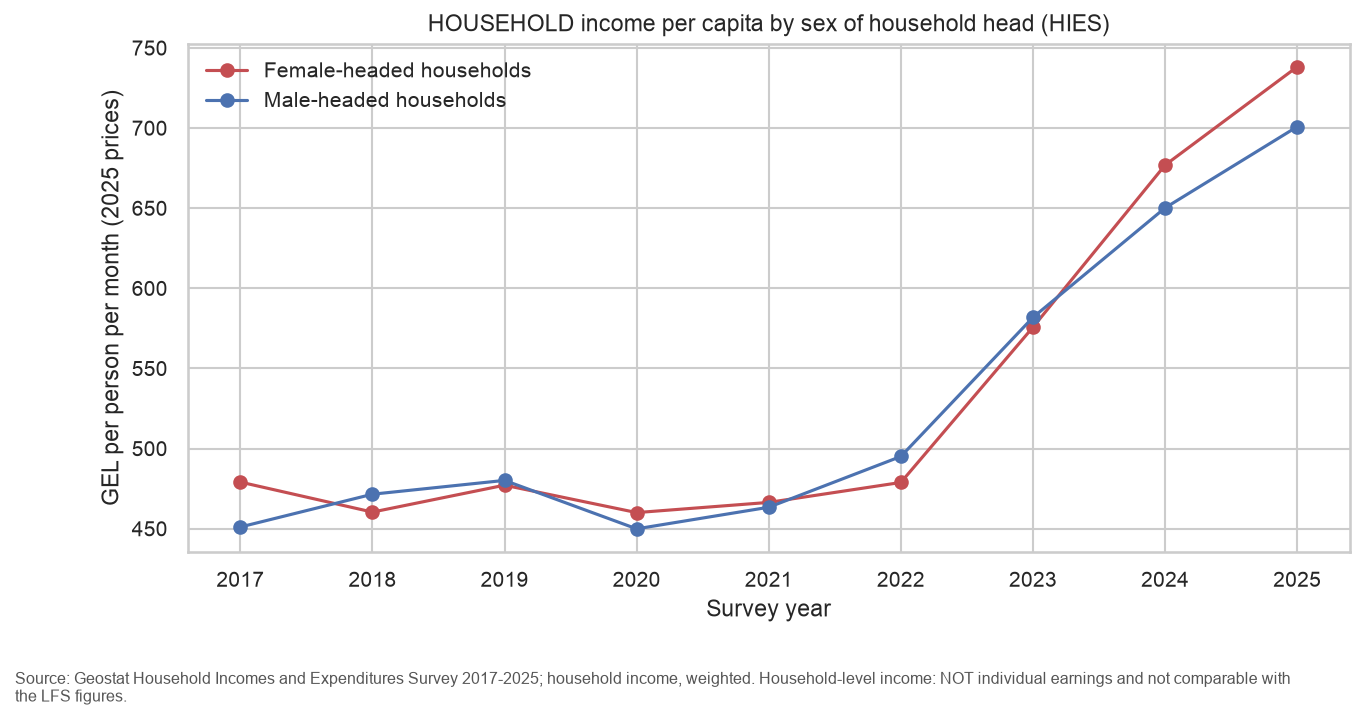

In [14]:
display(r['hies'])
display(Image('../reports/figures/14_hies_household_income_by_head_sex.png'))